1- Gaussian Mixture Models (GMMs) are a type of probabilistic model used for clustering and density estimation. 

2- They assist in representing data as a combination of different Gaussian distributions, where each distribution is characterized by its mean, covariance, and weight.

3- The Gaussian mixture model probability distribution class allows us to estimate the parameters of such a mixture distribution.

4-the GaussianMixture class is used for GMM-based clustering and density estimation. The covariances within GMMs play a vital role in shaping the individual Gaussian components of the mixture.

5- GaussianMixture includes several parameters such as n_components, covariance_type, tol, reg_covar, max_iter, n_init, init_params, weights_init, means_init, precisions_init, random_state, warm_start, verbose, and verbose_interval.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas import DataFrame
from sklearn import datasets
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA

# iris dataset

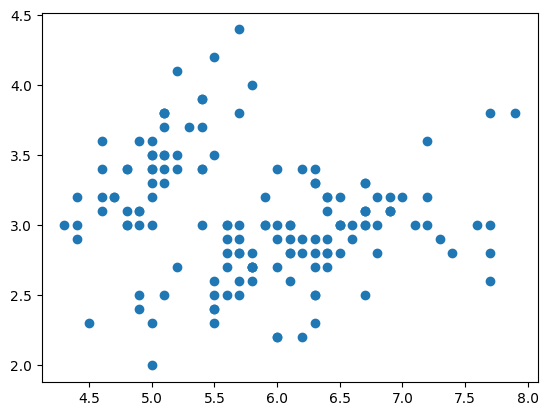

In [2]:
# load the iris dataset
iris = datasets.load_iris()
 
# select first two columns 
X = iris.data[:, :2]
 
# turn it into a dataframe
d = pd.DataFrame(X)
 
# plot the data
plt.scatter(d[0], d[1])
plt.show()

1- Number of Components: This parameter determines the number of components in our model, and it reflects the number of clusters or distributions the data will be divided into.


2- Covariance Type: The covariance type defines the structure of the covariance matrix for each component. 

3- It can be set to one of the four options: full, tied, diag, or spherical.

    a- Full: Each component has its own general covariance matrix, allows each component to have a unique shape, orientation, and size in all dimensions.

    b- Tied: All components share the same general covariance matrix, forces all components to share the same shape and orientation, promoting a more spherical distribution.

    c- Diag: Each component has its own diagonal covariance matrix, permits components to have different variances along each dimension but assumes no correlation between dimensions.

    d- Spherical: Each component has its own single variance, assumes that the shape of each component is spherical, with a single variance for all dimensions

c:\Users\Mahmoud\anaconda3\envs\py310\lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


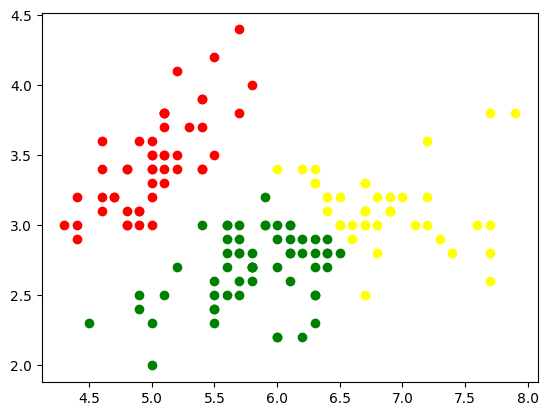

In [3]:
gmm = GaussianMixture(n_components = 3)

# Fit the GMM model for the dataset which expresses the dataset as a mixture of 3 Gaussian Distribution
gmm.fit(d)

# Assign a label to each sample
labels = gmm.predict(d)
d['labels']= labels
d0 = d[d['labels']== 0]
d1 = d[d['labels']== 1]
d2 = d[d['labels']== 2]

# plot three clusters in same plot
plt.scatter(d0[0], d0[1], c ='r')
plt.scatter(d1[0], d1[1], c ='yellow')
plt.scatter(d2[0], d2[1], c ='g')
plt.show()

In [4]:
 # print the converged log-likelihood value
print(gmm.lower_bound_)
 
# print the number of iterations needed for the log-likelihood value to converge
print(gmm.n_iter_)

-1.4987505566235169
8


Hence, it needed 7 iterations for the log-likelihood to converge. If more iterations are performed, no appreciable change in the log-likelihood value can be observed.

# Wine Dataset

In [3]:
# Data Preparation Load the wine dataset
wine = datasets.load_wine()
X = wine.data[:, :2]

In [7]:
n_components = 2  # Number of clusters
covariance_types = ['full', 'tied', 'diag', 'spherical']

In [8]:
# Initialize GMM models for each covariance type
gmm_models = {cov_type: GaussianMixture(n_components=n_components, covariance_type=cov_type)
              for cov_type in covariance_types}
 
# Fitting the GMM Models و Fit GMM models for each covariance type
for cov_type, gmm_model in gmm_models.items():
    gmm_model.fit(X)

c:\Users\Mahmoud\anaconda3\envs\py310\lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Mahmoud\anaconda3\envs\py310\lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Mahmoud\anaconda3\envs\py310\lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Mahmoud\anaconda3\envs\py310\lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarn

In [9]:
covariances = {cov_type: gmm_model.covariances_
               for cov_type, gmm_model in gmm_models.items()}
covariances

{'full': array([[[0.56212312, 0.35649231],
         [0.35649231, 1.20287491]],
 
        [[0.65850482, 0.14306183],
         [0.14306183, 0.08963565]]]),
 'tied': array([[0.65472811, 0.06104194],
        [0.06104194, 0.32378235]]),
 'diag': array([[0.458586  , 0.86305236],
        [0.77474996, 0.13054888]]),
 'spherical': array([0.52565557, 0.51107262])}

In [10]:

# Predict the cluster assignments for all data points
predictions = {cov_type: gmm_model.predict(X)
               for cov_type, gmm_model in gmm_models.items()}

In [11]:
predictions

{'full': array([1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0,
        1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0,
        1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0,
        0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1,
        0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0,
        0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0], dtype=int64),
 'tied': array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0,
        1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,

1- The BIC score is a measure of how well a model fits the data while also penalizing for model complexity. 

2- In general, a lower BIC score indicates a better model.

Covariance Matrix (full - Component):
[[0.56212312 0.35649231]
 [0.35649231 1.20287491]]
Covariance Matrix (tied - Component):
[0.65472811 0.06104194]
Covariance Matrix (diag - Component):
[0.458586   0.86305236]
Covariance Matrix (spherical - Component):
0.5256555694952098


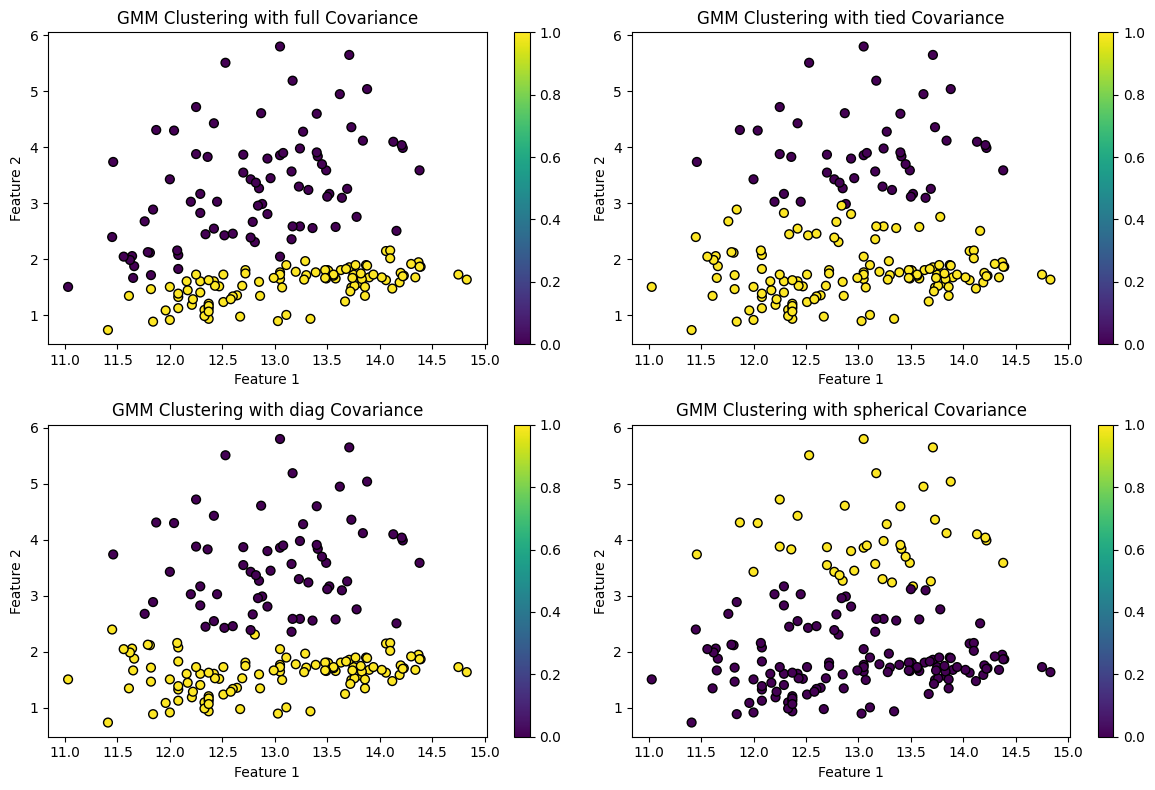

In [12]:
# Plot the clusters for each covariance type
plt.figure(figsize=(12, 8))
 
for i, (cov_type, gmm_model) in enumerate(gmm_models.items(), 1):
    plt.subplot(2, 2, i)
    plt.scatter(X[:, 0], X[:, 1], c=predictions[cov_type], cmap='viridis', edgecolors='k', s=40)
    plt.title(f'GMM Clustering with {cov_type} Covariance')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.colorbar()
     
    # Print the covariance matrix for the first component (adjust as needed)
    print(f'Covariance Matrix ({cov_type} - Component):\n{covariances[cov_type][0]}')
 
plt.tight_layout()
plt.show()

1- The plots show that using full covariance generally leads to a better BIC score than using tied, diagonal, or spherical covariance. 

2- This means that using full covariance allows the model to better capture the data’s true distribution, even if it comes at the cost of being more complex.

3- However, there are some exceptions. For example, in the plot for Feature 2, using tied covariance results in a lower BIC score than using full covariance for a small number of clusters. 

4- This suggests that the data in Feature 2 may be well-represented by a simpler model in this case.

5- Overall, the choice of covariance structure can have a significant impact on the performance of GMM clustering. It is important to experiment with different options to find the one that best fits the data. 

6- Choosing an appropriate covariance type is often task-dependent.

7- For datasets with varying shapes and orientations, ‘full’ covariance might be more suitable. 

8- In cases where components are expected to have similar shapes, ‘tied’ or ‘spherical’ covariance might be more appropriate.



In [ ]:
import numpy as np

bic_scores = []
k_range = range(1, 10)

for k in k_range:
    gmm = GaussianMixture(n_components=k , covariance_type='full')
    gmm.fit(X)
    bic_scores.append(gmm.bic(X))

best_k = k_range[np.argmin(bic_scores)]

In [5]:
best_k

3